# Acne improvement, Phase 2: final training (3 seeds), average, threshold, development test once

**What it does.** Trains the chosen configuration with three seeds (42, 7, 123), averages the three models' boxes, picks the confidence threshold on the 154 **validation** photos, and scores the 167-photo development test **once** (stored in a lock file).
**Before you run it:** open Phase 1's result table and set `CONFIG` below to the winning settings (only experiments that passed the +0.02 rule). The default is the baseline recipe (no change).

**Time:** about 2 to 3.5 hours (3 seeds). 

**Before you start (important):**
- Make sure no other training is running (`ps aux | grep -E "nbconvert|lesion_exp"` in WSL). WSL has only about 6.7 GB of memory; two trainings at once can freeze or crash both.
- Kernel: choose the WSL environment `.venv_det` (Python 3.11).
- Run the cells in order. Every finished epoch prints one line; `*` marks a new best mAP@0.5.
- Close other heavy programs (browsers with many tabs, other notebooks) while training.

In [1]:
import os, sys, json, time, shutil
os.environ["YOLO_VERBOSE"] = "False"          # no progress bars: one clean line per finished epoch is printed instead
from pathlib import Path
sys.path[:0] = ["/mnt/c/Users/Bautista/source/repos/SkinDevApp/" + _d for _d in ("shared", "acne/scripts", "hyperpigmentation/scripts", "eczema/scripts", "skintone", "gradcam")]
HOME = Path.home() / "PrecisionSkinV1"

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lesion_exp as LE
QUICK_TEST = False                    # True = 1 epoch of seed 42 only, throw-away folder: checks that everything works
TRAIN = True                          # False = only show the results of runs that already finished
ALLOW_RESCORE = False                 # the development test is scored once, then the stored result is shown
# ---- set this after Phase 1 (only changes that passed the rule) ----
CONFIG = dict(name="960_lowlr", recipe="acne_base", over=dict(imgsz=960, batch=6, lr0=0.0005, optimizer="AdamW"))        # = Phase 1 E1: best validation score (+0.027) but recall 0.003 short of the rule; run as a candidate, compared with the installed baseline average in the summary
SEEDS = [42, 7, 123]
IMGSZ = CONFIG["over"].get("imgsz", 800)
TAG = "acne_final_" + CONFIG["name"]
if QUICK_TEST: SEEDS = [42]; TAG += "_QUICKTEST"
VAL_DIR, TEST_DIR = LE.ACNE / "val", LE.ACNE / "test"
LOCK = HOME / "runs" / (TAG + "_devtest_scored.json")
print("configuration:", CONFIG, "| image size", IMGSZ, "| seeds", SEEDS, "| run names start with", TAG)

configuration: {'name': '960_lowlr', 'recipe': 'acne_base', 'over': {'imgsz': 960, 'batch': 6, 'lr0': 0.0005, 'optimizer': 'AdamW'}} | image size 960 | seeds [42, 7, 123] | run names start with acne_final_960_lowlr


## 1. Toolbox
Helper functions for boxes, matching, precision / recall / F1, model averaging and plots (nothing here trains).

In [2]:
import json, csv, os, sys, time, shutil, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
warnings.filterwarnings("ignore")
EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def rd(p):
    p = Path(p); return [tuple(map(float, l.split()[1:5])) for l in p.read_text().splitlines() if len(l.split()) >= 5] if p.exists() else []
def xyxy(b): return b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
def iou(a, b):
    a, b = xyxy(a), xyxy(b); iw, ih = max(0, min(a[2], b[2]) - max(a[0], b[0])), max(0, min(a[3], b[3]) - max(a[1], b[1])); i = iw * ih
    return i / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i + 1e-12)
def side(b): return (b[2] * b[3]) ** 0.5
def images_of(d): return sorted(p for p in (Path(d) / "images").glob("*") if p.suffix.lower() in EXT)

def raw_preds(weights, d, imgsz=800):
    """all boxes down to confidence 0.001 for every photo of folder d (normalised x-centre, y-centre, w, h)"""
    from ultralytics import YOLO
    import torch
    m = YOLO(str(weights)); dev = 0 if torch.cuda.is_available() else "cpu"; out = {}; ims = images_of(d)
    for s in range(0, len(ims), 8):
        ch = ims[s:s + 8]
        for p, r in zip(ch, m.predict([str(x) for x in ch], imgsz=imgsz, conf=0.001, iou=0.6, max_det=300, verbose=False, device=dev)):
            out[p.name] = [(tuple(map(float, b)), float(c)) for b, c in zip(r.boxes.xywhn.cpu().numpy(), r.boxes.conf.cpu().numpy())] if len(r.boxes) else []
    return out

def fuse(lists, thr=0.5):
    """weighted box fusion: boxes of the models that overlap (IoU >= thr) become one box; confidence = sum of confidences / number of models"""
    n = len(lists); allb = sorted([b for l in lists for b in l], key=lambda x: -x[1]); clusters = []
    for b, c in allb:
        for cl in clusters:
            if iou(cl["box"], b) >= thr:
                cl["m"].append((b, c)); w = np.array([x[1] for x in cl["m"]]); cl["box"] = tuple(np.average(np.array([x[0] for x in cl["m"]]), axis=0, weights=w)); break
        else: clusters.append({"box": b, "m": [(b, c)]})
    return [(cl["box"], min(1.0, sum(x[1] for x in cl["m"]) / n)) for cl in clusters]

def _ap(conf, tp, n_gt):
    if n_gt == 0 or len(conf) == 0: return 0.0
    o = np.argsort(-conf); tp = tp[o]; tpc = np.cumsum(tp); fpc = np.cumsum(1 - tp); rec = tpc / n_gt; prec = tpc / (tpc + fpc)
    mrec = np.concatenate([[0], rec, [1]]); mpre = np.concatenate([[1], prec, [0]]); mpre = np.flip(np.maximum.accumulate(np.flip(mpre))); x = np.linspace(0, 1, 101)
    return float(np.trapezoid(np.interp(x, mrec, mpre), x)) if hasattr(np, "trapezoid") else float(np.trapz(np.interp(x, mrec, mpre), x))

def match_flags(gt, pr, thr):
    """greedy by confidence: returns (confidences, 1/0 true-positive flags) of every predicted box of one photo"""
    used = set(); cs, fl = [], []
    for b, c in sorted(pr, key=lambda x: -x[1]):
        best, bj = 0, -1
        for j, g in enumerate(gt):
            if j in used: continue
            v = iou(g, b)
            if v > best: best, bj = v, j
        ok = bj >= 0 and best >= thr
        if ok: used.add(bj)
        cs.append(c); fl.append(1.0 if ok else 0.0)
    return cs, fl

def score(preds, d):
    """mAP@0.5, mAP@0.5:0.95 and the raw arrays for precision / recall / F1 at any confidence (ground truth = labels of folder d)"""
    d = Path(d); gts = {k: rd(d / "labels" / (Path(k).stem + ".txt")) for k in preds}; n_gt = sum(len(g) for g in gts.values()); aps = []; conf50 = tp50 = None
    for t in np.arange(0.5, 0.96, 0.05):
        cs, fl = [], []
        for k, pr in preds.items():
            c, f = match_flags(gts[k], pr, t); cs += c; fl += f
        cs, fl = np.array(cs), np.array(fl); aps.append(_ap(cs, fl, n_gt))
        if abs(t - 0.5) < 1e-9: conf50, tp50 = cs, fl
    return dict(AP50=aps[0], AP50_95=float(np.mean(aps)), conf=conf50, tp=tp50, n_gt=n_gt)

def at_conf(s, c):
    m = s["conf"] >= c; tp = s["tp"][m].sum(); p = tp / max(1, m.sum()); r = tp / max(1, s["n_gt"]); return p, r, 2 * p * r / max(1e-9, p + r)

def best_conf(s):
    cs = np.arange(0.05, 0.9, 0.025); return float(max(cs, key=lambda c: at_conf(s, c)[2]))

def rows_at(preds, d, thr):
    """per photo: true positives, false positives, false negatives, zones of your boxes, zones of the model boxes, n your boxes, n model boxes"""
    rows = []
    for k, pr in preds.items():
        gt = rd(Path(d) / "labels" / (Path(k).stem + ".txt")); pc = [b for b, c in pr if c >= thr]; _, fl = match_flags(gt, [(b, 1.0) for b in pc], 0.5); tp = int(sum(fl))
        cell = lambda b: min(2, int(b[1] * 3)) * 3 + min(2, int(b[0] * 3))
        rows.append((tp, len(pc) - tp, len(gt) - tp, {cell(g) for g in gt}, {cell(b) for b in pc}, len(gt), len(pc)))
    return rows

def prf(rows):
    tp, fp, fn = sum(r[0] for r in rows), sum(r[1] for r in rows), sum(r[2] for r in rows); p, r = tp / max(1, tp + fp), tp / max(1, tp + fn); return p, r, 2 * p * r / max(1e-9, p + r)

def zone_f1(rows):
    tp = sum(len(r[3] & r[4]) for r in rows); fp = sum(len(r[4] - r[3]) for r in rows); fn = sum(len(r[3] - r[4]) for r in rows); return 2 * tp / max(1, 2 * tp + fp + fn)

def f1_by_iou(preds, d, thr, ious=(0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)):
    out = {}
    for t in ious:
        tp = fp = fn = 0
        for k, pr in preds.items():
            gt = rd(Path(d) / "labels" / (Path(k).stem + ".txt")); pc = [(b, 1.0) for b, c in pr if c >= thr]; _, fl = match_flags(gt, pc, t); x = int(sum(fl)); tp += x; fp += len(pc) - x; fn += len(gt) - x
        p, r = tp / max(1, tp + fp), tp / max(1, tp + fn); out[t] = 2 * p * r / max(1e-9, p + r)
    return out

def bootstrap_f1(rows, n=1000, seed=0):
    rng = np.random.default_rng(seed); idx = np.arange(len(rows)); b = [prf([rows[i] for i in rng.choice(idx, len(idx))])[2] for _ in range(n)]; return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

def show_examples(preds, d, thr, names, cols=4, title=""):
    d = Path(d); fig, ax = plt.subplots(-(-len(names) // cols), cols, figsize=(4 * cols, 4 * -(-len(names) // cols))); ax = np.array(ax).reshape(-1)
    for a in ax: a.axis("off")
    for a, n in zip(ax, names):
        p = next(iter((d / "images").glob(Path(n).stem + ".*"))); im = Image.open(p).convert("RGB"); W, H = im.size; dr = ImageDraw.Draw(im); lw = max(2, W // 250)
        for b in rd(d / "labels" / (Path(n).stem + ".txt")): x0, y0, x1, y1 = xyxy(b); dr.rectangle([x0 * W, y0 * H, x1 * W, y1 * H], outline=(40, 220, 60), width=lw)
        for b, c in preds[n]:
            if c >= thr: x0, y0, x1, y1 = xyxy(b); dr.rectangle([x0 * W, y0 * H, x1 * W, y1 * H], outline=(255, 40, 40), width=lw)
        a.imshow(im); a.set_title(n[:28], fontsize=8)
    fig.suptitle(title + "  (green = your boxes, red = model boxes above the threshold)"); plt.tight_layout(); plt.show()

def curves(run_dirs, labels):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for rd_, lb in zip(run_dirs, labels):
        f = Path(rd_) / "results.csv"
        if not f.exists(): continue
        r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]
        ax[0].plot(r["epoch"], r["train/box_loss"], label=lb + " train"); ax[0].plot(r["epoch"], r["val/box_loss"], "--", label=lb + " val")
        ax[1].plot(r["epoch"], r["metrics/mAP50(B)"], label=lb); ax[2].plot(r["epoch"], r["metrics/mAP50-95(B)"], label=lb)
    for a, t in zip(ax, ("box loss (training = solid, validation = dashed)", "validation mAP@0.5", "validation mAP@0.5:0.95")): a.set_title(t, fontsize=10); a.set_xlabel("epoch"); a.legend(fontsize=7); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 2. Training function

In [3]:
def train_run(run_id, recipe, over, note, seed, args_base=None, quick=False):
    """one training run with a clean per-epoch line; resumable; returns the run folder"""
    import yaml, torch
    from ultralytics import YOLO
    sp = LE.spec(run_id, "acne", recipe, note, seed=seed, **over); train, vals, _ = LE.recipe(recipe); args = dict(sp["args"]); model = args.pop("model")
    if quick: args["epochs"] = 1
    run = LE.RUNS / run_id; run.mkdir(parents=True, exist_ok=True); lst = run / "train_list.txt"; lst.write_text("\n".join(str(p) for p in train) + "\n")
    first_val = next(iter(vals.values())); yml = run / "data.yaml"
    yaml.safe_dump({"path": str(run), "train": str(lst), "val": str(first_val / "images"), "names": {0: "acne"}}, open(yml, "w")); (run / "spec.json").write_text(json.dumps(sp, indent=1))
    best = {"v": 0.0}
    def on_epoch(trainer):
        m = trainer.metrics; ls = trainer.label_loss_items(trainer.tloss, prefix="train"); mp = m.get("metrics/mAP50(B)", 0.0); star = "*" if mp > best["v"] else " "; best["v"] = max(best["v"], mp)
        print("%s epoch %3d/%d | box %.3f cls %.3f dfl %.3f | P %.3f R %.3f mAP50 %.3f mAP50-95 %.3f" % (star, trainer.epoch + 1, trainer.epochs, ls["train/box_loss"], ls["train/cls_loss"], ls["train/dfl_loss"],
              m.get("metrics/precision(B)", 0), m.get("metrics/recall(B)", 0), mp, m.get("metrics/mAP50-95(B)", 0)), flush=True)
    t0 = time.time(); last = run / "weights" / "last.pt"; print("=" * 110); print(run_id, "|", note, "| %d training images | seed %d" % (len(train), seed), flush=True)
    if (run / "DONE").exists(): print("already trained: using the saved run"); return run
    mdl = YOLO(str(last)) if last.exists() else YOLO(model); mdl.add_callback("on_fit_epoch_end", on_epoch)
    if last.exists(): mdl.train(resume=True)
    else: mdl.train(data=str(yml), seed=seed, device=0 if torch.cuda.is_available() else "cpu", project=str(LE.RUNS), name=run_id, exist_ok=True, plots=False, **args)
    (run / "DONE").write_text("ok"); print("trained in %.1f minutes" % ((time.time() - t0) / 60), flush=True); return run

## 3. Train the three seeds

In [4]:
RUNS = {}
for s in SEEDS:
    rid = "%s_seed%d" % (TAG, s)
    if TRAIN: train_run(rid, CONFIG["recipe"], CONFIG["over"], "final acne model, configuration %s, seed %d" % (CONFIG["name"], s), seed=s, quick=QUICK_TEST)
    RUNS[s] = LE.RUNS / rid
WEIGHTS = {s: RUNS[s] / "weights" / "best.pt" for s in SEEDS}; print({s: p.exists() for s, p in WEIGHTS.items()})

acne_final_960_lowlr_seed42 | final acne model, configuration 960_lowlr, seed 42 | 1145 training images | seed 42


* epoch   1/100 | box 1.944 cls 2.417 dfl 1.583 | P 0.360 R 0.353 mAP50 0.284 mAP50-95 0.083


* epoch   2/100 | box 1.740 cls 1.748 dfl 1.427 | P 0.400 R 0.397 mAP50 0.329 mAP50-95 0.098


* epoch   3/100 | box 1.680 cls 1.655 dfl 1.381 | P 0.384 R 0.428 mAP50 0.338 mAP50-95 0.105


  epoch   4/100 | box 1.662 cls 1.621 dfl 1.355 | P 0.387 R 0.414 mAP50 0.317 mAP50-95 0.094


...

  epoch  68/100 | box 1.320 cls 0.939 dfl 1.167 | P 0.484 R 0.472 mAP50 0.394 mAP50-95 0.121


  epoch  69/100 | box 1.299 cls 0.916 dfl 1.158 | P 0.513 R 0.472 mAP50 0.403 mAP50-95 0.125


  epoch  70/100 | box 1.299 cls 0.916 dfl 1.158 | P 0.503 R 0.483 mAP50 0.428 mAP50-95 0.139


trained in 34.9 minutes


{42: True, 7: True, 123: True}


## 4. Training curves and every finished epoch

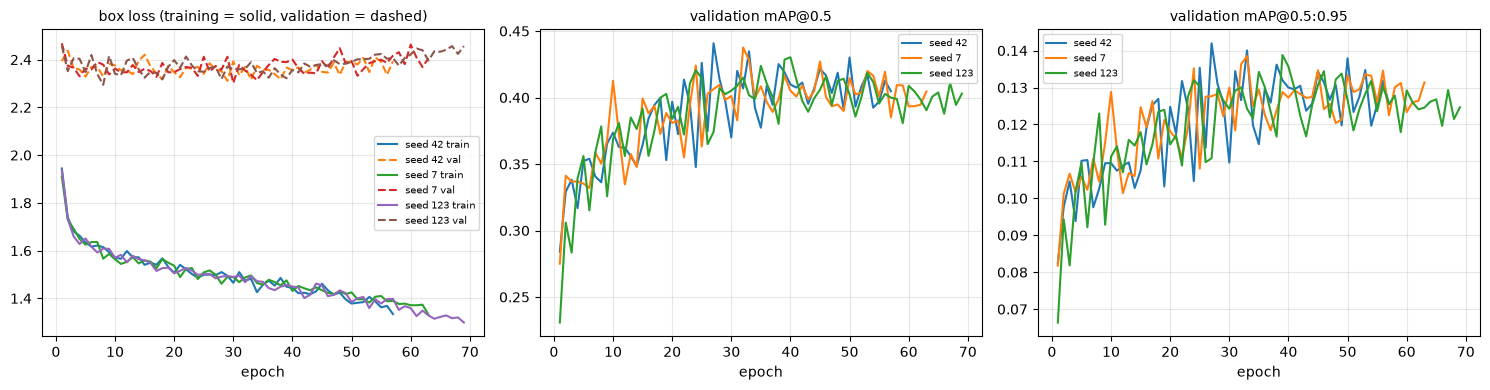

In [5]:
curves([RUNS[s] for s in SEEDS], ["seed %d" % s for s in SEEDS])

In [6]:
pd.set_option("display.max_rows", None); pd.set_option("display.width", 220)
cols = {"epoch": "epoch", "train/box_loss": "box_loss", "train/cls_loss": "cls_loss", "train/dfl_loss": "dfl_loss", "metrics/precision(B)": "P", "metrics/recall(B)": "R", "metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50-95"}
for s in SEEDS:
    f = RUNS[s] / "results.csv"
    if not f.exists(): print("seed", s, ": no results yet"); continue
    r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]; t = r[list(cols)].rename(columns=cols); t["epoch"] = t["epoch"].astype(int); t["best so far"] = np.where(t["mAP50"] == t["mAP50"].cummax(), "*", "")
    print("=" * 100); print("seed %d | %d finished epochs | best mAP@0.5 %.3f at epoch %d" % (s, len(t), t["mAP50"].max(), int(t.loc[t["mAP50"].idxmax(), "epoch"]))); display(t.round(3).set_index("epoch"))

seed 42 | 57 finished epochs | best mAP@0.5 0.441 at epoch 27


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,best so far
epoch,,,,,,,,
1,1.944,2.417,1.583,0.360,0.353,0.284,0.083,*
2,1.740,1.748,1.427,0.400,0.397,0.329,0.098,*
3,1.680,1.655,1.381,0.384,0.428,0.338,0.105,*
4,1.662,1.621,1.355,0.387,0.414,0.317,0.094,
5,1.635,1.580,1.360,0.426,0.405,0.352,0.110,*
6,1.617,1.555,1.324,0.431,0.397,0.354,0.110,*
7,1.621,1.640,1.365,0.401,0.422,0.341,0.098,
8,1.615,1.577,1.329,0.425,0.373,0.336,0.103,
9,1.593,1.510,1.317,0.393,0.435,0.366,0.110,*


seed 7 | 63 finished epochs | best mAP@0.5 0.438 at epoch 32


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,best so far
epoch,,,,,,,,
1,1.910,2.079,1.547,0.362,0.338,0.275,0.082,*
2,1.729,1.804,1.428,0.420,0.384,0.341,0.101,*
3,1.691,1.693,1.373,0.409,0.395,0.337,0.107,
4,1.649,1.674,1.375,0.395,0.442,0.337,0.102,
5,1.625,1.554,1.365,0.405,0.387,0.335,0.106,
6,1.636,1.593,1.359,0.401,0.417,0.332,0.102,
7,1.636,1.557,1.357,0.430,0.403,0.359,0.111,*
8,1.566,1.496,1.311,0.416,0.432,0.350,0.104,
9,1.586,1.481,1.321,0.418,0.418,0.368,0.115,*


seed 123 | 69 finished epochs | best mAP@0.5 0.430 at epoch 40


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,best so far
epoch,,,,,,,,
1,1.938,2.149,1.561,0.320,0.305,0.231,0.066,*
2,1.733,1.782,1.429,0.369,0.390,0.306,0.094,*
3,1.659,1.677,1.371,0.335,0.399,0.283,0.082,
4,1.628,1.564,1.370,0.395,0.412,0.339,0.102,*
5,1.651,1.559,1.366,0.407,0.426,0.356,0.110,*
6,1.617,1.513,1.341,0.387,0.396,0.315,0.092,
7,1.592,1.549,1.315,0.429,0.430,0.359,0.110,*
8,1.608,1.550,1.342,0.432,0.441,0.378,0.123,*
9,1.607,1.516,1.330,0.392,0.428,0.326,0.093,


## 5. Validation results per seed, the 3-model average, and the threshold (chosen on validation only)

,seed,mAP50,mAP50_95,threshold,precision,recall,F1
0,42,0.452,0.144,0.250,0.508,0.482,0.495
1,7,0.437,0.141,0.325,0.506,0.475,0.490
2,123,0.436,0.141,0.250,0.502,0.485,0.493


mean mAP@0.5 0.442 (std 0.009)


3-model average on validation: mAP@0.5 0.471 | mAP@0.5:0.95 0.148 | best F1 0.513 at threshold 0.225 (precision 0.487, recall 0.542)


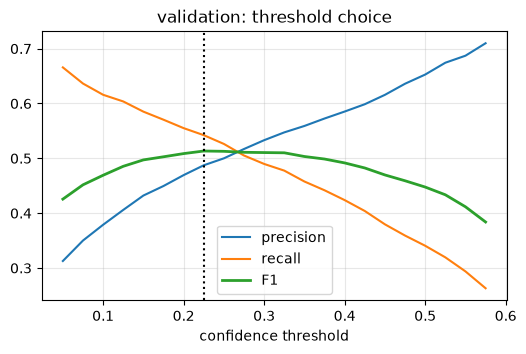

In [7]:
VAL_PRED = {s: raw_preds(WEIGHTS[s], VAL_DIR, IMGSZ) for s in SEEDS}; rows = []
for s in SEEDS:
    sc = score(VAL_PRED[s], VAL_DIR); c = best_conf(sc); p, r, f = at_conf(sc, c); rows.append(dict(seed=s, mAP50=sc["AP50"], mAP50_95=sc["AP50_95"], threshold=c, precision=p, recall=r, F1=f))
vt = pd.DataFrame(rows); display(vt.round(3)); print("mean mAP@0.5 %.3f (std %.3f)" % (vt.mAP50.mean(), vt.mAP50.std() if len(vt) > 1 else 0))
FUSED_VAL = {k: fuse([VAL_PRED[s][k] for s in SEEDS]) for k in VAL_PRED[SEEDS[0]]}; sv = score(FUSED_VAL, VAL_DIR); THR = best_conf(sv); p, r, f = at_conf(sv, THR)
print("3-model average on validation: mAP@0.5 %.3f | mAP@0.5:0.95 %.3f | best F1 %.3f at threshold %.3f (precision %.3f, recall %.3f)" % (sv["AP50"], sv["AP50_95"], f, THR, p, r))
cs = np.arange(0.05, 0.6, 0.025); pr_ = [at_conf(sv, c) for c in cs]
plt.figure(figsize=(6, 3.5)); plt.plot(cs, [x[0] for x in pr_], label="precision"); plt.plot(cs, [x[1] for x in pr_], label="recall"); plt.plot(cs, [x[2] for x in pr_], label="F1", lw=2)
plt.axvline(THR, color="k", ls=":"); plt.xlabel("confidence threshold"); plt.legend(); plt.grid(alpha=.3); plt.title("validation: threshold choice"); plt.show()

## 6. Development test (167 photos), scored once
This set influenced earlier decisions, so treat it as a development number. The independent claim is made in Phase 3 on the fresh test set.

In [8]:
if LOCK.exists() and not ALLOW_RESCORE:
    R = json.loads(LOCK.read_text()); print("stored result from", R["scored_at"])
else:
    TEST_PRED = {s: raw_preds(WEIGHTS[s], TEST_DIR, IMGSZ) for s in SEEDS}; FUSED_TEST = {k: fuse([TEST_PRED[s][k] for s in SEEDS]) for k in TEST_PRED[SEEDS[0]]}
    st = score(FUSED_TEST, TEST_DIR); rows_t = rows_at(FUSED_TEST, TEST_DIR, THR); p, r, f = prf(rows_t); lo, hi = bootstrap_f1(rows_t); singles = [score(TEST_PRED[s], TEST_DIR)["AP50"] for s in SEEDS]
    R = dict(scored_at=time.strftime("%Y-%m-%d %H:%M"), config=CONFIG["name"], threshold=THR, mAP50=st["AP50"], mAP50_95=st["AP50_95"], precision=p, recall=r, F1=f, F1_ci=[lo, hi], zone_F1=zone_f1(rows_t), single_seed_mAP50=singles,
             n_photos=len(FUSED_TEST), val_mAP50_avg=sv["AP50"])
    LOCK.parent.mkdir(parents=True, exist_ok=True); LOCK.write_text(json.dumps(R, indent=1)); print("scored and stored in", LOCK)
print("DEVELOPMENT TEST (%d photos), 3-model average at threshold %.3f" % (R["n_photos"], R["threshold"]))
print("  mAP@0.5 %.3f | mAP@0.5:0.95 %.3f | precision %.3f | recall %.3f | F1 %.3f (95%% range %.2f-%.2f) | zone F1 %.3f" % (R["mAP50"], R["mAP50_95"], R["precision"], R["recall"], R["F1"], *R["F1_ci"], R["zone_F1"]))
print("  single seeds, mAP@0.5:", [round(x, 3) for x in R["single_seed_mAP50"]], "| installed model before: mAP@0.5 0.439, F1 0.507 (3-seed average, baseline recipe)")

scored and stored in /home/bautista/PrecisionSkinV1/runs/acne_final_960_lowlr_devtest_scored.json
DEVELOPMENT TEST (167 photos), 3-model average at threshold 0.225
  mAP@0.5 0.481 | mAP@0.5:0.95 0.138 | precision 0.454 | recall 0.601 | F1 0.517 (95% range 0.48-0.55) | zone F1 0.831
  single seeds, mAP@0.5: [0.453, 0.43, 0.436] | installed model before: mAP@0.5 0.439, F1 0.507 (3-seed average, baseline recipe)


## 7. Export for the app (optional, only after you decide to install)
Off by default. If you turn it on, the files go to `SkinDevApp/Model` and **replace the installed acne models**. The image size must match (960 px models need `imgsz` 960 in the json and the same size in the export). Tell Claude before installing so the app's threshold and the check through the C# code are done too.

In [9]:
EXPORT = False
if EXPORT:
    from ultralytics import YOLO
    MODEL_DIR = Path("/mnt/c/Users/Bautista/source/repos/SkinDevApp/SkinDevApp/Model")
    for suffix, s in (("", SEEDS[0]), ("_m2", SEEDS[1]), ("_m3", SEEDS[2])):
        o = Path(YOLO(str(WEIGHTS[s])).export(format="onnx", imgsz=IMGSZ, opset=12, simplify=True, dynamic=False)); shutil.copy2(o, MODEL_DIR / ("lesion_detector_acne%s.onnx" % suffix)); print("exported seed", s)
    print("now set default_conf = %.3f, imgsz = %d and nms_iou = 0.6 in lesion_detector_acne.json" % (THR, IMGSZ))
else: print("EXPORT = False: nothing written")

EXPORT = False: nothing written
